# MNIST Image Classification Using CNN

## Project Overview

This project builds a convolutional neural network (CNN) to classify handwritten digits from the MNIST dataset.

The workflow includes loading and inspecting the image data, preprocessing the images, building and training a CNN, evaluating test accuracy, reviewing training performance, and analyzing classification errors with a confusion matrix.

## Business Problem

Organizations that digitize handwritten information need to convert handwritten numerals into machine-readable data accurately and efficiently. Manual transcription is time-consuming, and recognition errors can create additional verification work. This project examines whether a convolutional neural network can reliably recognize digits in standardized grayscale images.

## Business Objectives

- Develop an automated classifier for handwritten digits from 0 through 9.
- Prepare image data consistently for model training and evaluation.
- Evaluate classification performance on a held-out test set.
- Identify common digit confusions to inform quality-control decisions.
- Save the trained model for reproducible use and further experimentation.

## Technical Approach

Use the MNIST dataset, normalize 28 × 28 grayscale images, train a convolutional neural network, assess training and validation behavior, evaluate test accuracy and loss, and inspect a confusion matrix. The notebook demonstrates a prototype rather than a production document-processing system.


## 1. Import Libraries

In [1]:
from pathlib import Path
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
from tensorflow import keras
from tensorflow.keras import layers
from tensorflow.keras.datasets import mnist

warnings.filterwarnings("ignore")


## 2. Set Project Paths

In [2]:
CURRENT_DIR = Path.cwd()

# Support running from either the project root or the notebooks folder.
if CURRENT_DIR.name.lower() == "notebooks":
    PROJECT_DIR = CURRENT_DIR.parent
else:
    PROJECT_DIR = CURRENT_DIR

FIGURES_DIR = PROJECT_DIR / "figures"
RESULTS_DIR = PROJECT_DIR / "results"
MODELS_DIR = PROJECT_DIR / "models"

FIGURES_DIR.mkdir(parents=True, exist_ok=True)
RESULTS_DIR.mkdir(parents=True, exist_ok=True)
MODELS_DIR.mkdir(parents=True, exist_ok=True)

print("Project folders ready:")
print(" - figures/")
print(" - results/")
print(" - models/")


Project folders ready:
 - figures/
 - results/
 - models/


### Interpretation — Output directories

The notebook creates dedicated `figures/`, `results/`, and `models/` directories, separating charts, tabular evaluation results, and the trained neural network. This organization makes the analysis easier to reproduce and allows reviewers to locate deliverables without searching through notebook cells. The printed confirmation establishes that the required directories were available during this run.

## 3. Load the MNIST Dataset

In [3]:
(X_train, y_train), (X_test, y_test) = mnist.load_data()

print("MNIST dataset loaded successfully.")
print("Training set shape:", X_train.shape)
print("Test set shape:", X_test.shape)
print("Training labels shape:", y_train.shape)
print("Test labels shape:", y_test.shape)


MNIST dataset loaded successfully.
Training set shape: (60000, 28, 28)
Test set shape: (10000, 28, 28)
Training labels shape: (60000,)
Test labels shape: (10000,)


### Interpretation — Dataset dimensions

The training set contains **60,000** images and the test set contains **10,000** images. Each image is a **28 × 28** grayscale array, while each label is a single digit from **0 to 9**. Keeping the 10,000-image test set separate from model fitting provides an evaluation on examples not used for weight updates. These dimensions also confirm that the input data matches the architecture's expected image size; they do not, by themselves, indicate classification quality.

## 4. Preview Training Images

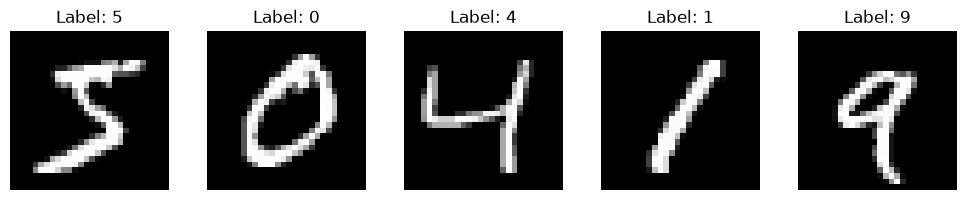

Saved: figures/mnist_sample_training_images.png


In [4]:
fig = plt.figure(figsize=(10, 2))

for i in range(5):
    plt.subplot(1, 5, i + 1)
    plt.imshow(X_train[i], cmap="gray")
    plt.title(f"Label: {y_train[i]}")
    plt.axis("off")

plt.tight_layout()

save_path = FIGURES_DIR / "mnist_sample_training_images.png"
plt.savefig(save_path, dpi=300, bbox_inches="tight")
plt.show()

print("Saved: figures/mnist_sample_training_images.png")


### Interpretation — Sample handwritten digits

The five displayed examples provide a visual check of the data before preprocessing. Each image is small, grayscale, and labeled with its corresponding digit. Variation in handwriting is important: the CNN must recognize digit shapes despite differences in stroke thickness, curvature, and positioning. This preview is illustrative rather than a statistical assessment of all 60,000 training images, so conclusions about class balance or overall difficulty should not be drawn from five examples.

## 5. Preprocess the Image Data

In [5]:
# Reshape images to include a single grayscale channel and normalize pixels.
X_train_cnn = (
    X_train.reshape(-1, 28, 28, 1)
    .astype("float32") / 255.0
)

X_test_cnn = (
    X_test.reshape(-1, 28, 28, 1)
    .astype("float32") / 255.0
)

# One-hot encode the class labels.
num_classes = 10

y_train_cat = keras.utils.to_categorical(
    y_train,
    num_classes
)

y_test_cat = keras.utils.to_categorical(
    y_test,
    num_classes
)

print("Data preprocessing completed successfully.")
print("Training input shape:", X_train_cnn.shape)
print("Test input shape:", X_test_cnn.shape)


Data preprocessing completed successfully.
Training input shape: (60000, 28, 28, 1)
Test input shape: (10000, 28, 28, 1)


### Interpretation — Image preprocessing

The input shape changes from **(60,000, 28, 28)** to **(60,000, 28, 28, 1)** for training, and similarly to **(10,000, 28, 28, 1)** for testing. The final dimension represents the single grayscale channel expected by the convolutional layers. Dividing pixel intensities by **255** scales them from the original 0–255 range to **0–1**, providing a consistent numerical scale for optimization. One-hot encoding converts each digit label into a ten-element target vector for categorical cross-entropy. The number of images remains unchanged; these are transformations of the existing observations, not additional samples.

## 6. Build the CNN Model

In [6]:
model = keras.Sequential([
    layers.Input(shape=(28, 28, 1)),
    layers.Conv2D(
        32,
        kernel_size=(3, 3),
        activation="relu"
    ),
    layers.Conv2D(
        64,
        kernel_size=(3, 3),
        activation="relu"
    ),
    layers.MaxPooling2D(
        pool_size=(2, 2)
    ),
    layers.Dropout(0.25),
    layers.Flatten(),
    layers.Dense(
        128,
        activation="relu"
    ),
    layers.Dropout(0.5),
    layers.Dense(
        num_classes,
        activation="softmax"
    )
])

model.compile(
    optimizer="adam",
    loss="categorical_crossentropy",
    metrics=["accuracy"]
)

model.summary()


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                      │ (None, 26, 26, 32)          │             320 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_1 (Conv2D)                    │ (None, 24, 24, 64)          │          18,496 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d (MaxPooling2D)         │ (None, 12, 12, 64)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout (Dropout)                    │ (None, 12, 12, 64)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ flatten (Flatten)                    │ (None, 9216)                │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense (Dense)                        │ (None, 128)                 │       1,179,776 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_1 (Dropout)                  │ (None, 128)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_1 (Dense)                      │ (None, 10)                  │           1,290 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 1,199,882 (4.58 MB)

 Trainable params: 1,199,882 (4.58 MB)

 Non-trainable params: 0 (0.00 B)

### Interpretation — CNN architecture and capacity

The model uses two **3 × 3 convolutional layers** with **32** and **64** filters to learn increasingly complex visual patterns. Max pooling reduces the feature-map dimensions, while dropout layers (**0.25** and **0.50**) randomly suppress activations during training to help limit reliance on individual features. After flattening, a **128-unit dense layer** combines learned features, and the **10-unit softmax output** produces class probabilities for digits 0–9. The model summary reports **1,199,882 trainable parameters**; most are in the dense layer after flattening. This capacity is sufficient to learn rich patterns, but the parameter count also makes monitoring validation performance important. Adam optimizes categorical cross-entropy, with accuracy used as a complementary performance measure.

## 7. Train the CNN Model

In [7]:
history = model.fit(
    X_train_cnn,
    y_train_cat,
    validation_split=0.10,
    epochs=5,
    batch_size=128,
    verbose=1
)

print("CNN training completed successfully.")


Epoch 1/5
422/422 ━━━━━━━━━━━━━━━━━━━━ 67s 153ms/step - accuracy: 0.9145 - loss: 0.2812 - val_accuracy: 0.9832 - val_loss: 0.0568
Epoch 2/5
422/422 ━━━━━━━━━━━━━━━━━━━━ 26s 60ms/step - accuracy: 0.9705 - loss: 0.1001 - val_accuracy: 0.9868 - val_loss: 0.0490
Epoch 3/5
422/422 ━━━━━━━━━━━━━━━━━━━━ 19s 44ms/step - accuracy: 0.9766 - loss: 0.0754 - val_accuracy: 0.9897 - val_loss: 0.0421
Epoch 4/5
422/422 ━━━━━━━━━━━━━━━━━━━━ 22s 52ms/step - accuracy: 0.9806 - loss: 0.0625 - val_accuracy: 0.9900 - val_loss: 0.0366
Epoch 5/5
422/422 ━━━━━━━━━━━━━━━━━━━━ 59s 141ms/step - accuracy: 0.9841 - loss: 0.0528 - val_accuracy: 0.9897 - val_loss: 0.0361
CNN training completed successfully.


### Interpretation — Training execution

The CNN completed **five epochs** using a batch size of **128** and a **10% validation split** from the original 60,000 training images. Approximately **54,000 images** contributed to parameter updates, while **6,000 images** were reserved for validation. The separate **10,000-image test set** was not used for training or validation.

The saved epoch results show training accuracy improving from **91.45%** in epoch 1 to **98.41%** in epoch 5, while training loss decreased from **0.2812** to **0.0528**. Validation accuracy increased from **98.32%** to **98.97%** over the same period, reaching its highest recorded value of **99.00% at epoch 4**. Validation loss decreased from **0.0568** to **0.0361** by epoch 5.

Together, these trends show substantial learning during the first five epochs. The validation results provide an initial check on performance outside the model's weight-update data, but the independent test set remains the appropriate basis for reporting final classification accuracy.

## 8. Review Training Performance

In [8]:
history_df = pd.DataFrame(history.history)
history_df.index = np.arange(
    1,
    len(history_df) + 1
)
history_df.index.name = "Epoch"

history_df.to_csv(
    RESULTS_DIR / "training_history.csv"
)

display(history_df.round(4))

print("Saved: results/training_history.csv")


,accuracy,loss,val_accuracy,val_loss
Epoch,,,,
1,0.9145,0.2812,0.9832,0.0568
2,0.9705,0.1001,0.9868,0.0490
3,0.9766,0.0754,0.9897,0.0421
4,0.9806,0.0625,0.9900,0.0366
5,0.9841,0.0528,0.9897,0.0361


Saved: results/training_history.csv


### Interpretation — Epoch-by-epoch performance table

The table records steady improvement in training performance: **accuracy rises from 0.9145 to 0.9841**, while **loss falls from 0.2812 to 0.0528**. The largest gain in training accuracy occurs between epochs 1 and 2, after which improvements become progressively smaller. This pattern is consistent with the network learning major digit features early and refining them in later epochs.

Validation accuracy increases from **0.9832** at epoch 1 to **0.9900** at epoch 4, then changes slightly to **0.9897** at epoch 5. That difference is only **0.0003**, or **0.03 percentage points**, so it should not be overstated. Importantly, validation loss **continues to decline** across all five epochs, reaching its lowest value of **0.0361 at epoch 5**. Therefore, the latest run does **not** show a final-epoch increase in validation loss.

Accuracy and loss capture different aspects of performance: accuracy measures the share of correct classifications, whereas cross-entropy loss is sensitive to the probabilities assigned to the true classes. The final epoch can therefore produce slightly lower validation accuracy while still improving validation loss. The saved `results/training_history.csv` provides the exact figures for subsequent comparison or reporting.

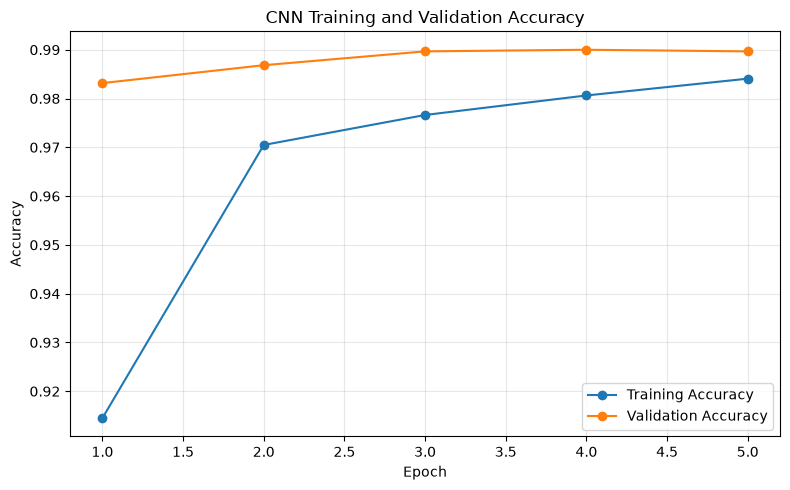

Saved: figures/training_validation_accuracy.png


In [9]:
plt.figure(figsize=(8, 5))

plt.plot(
    history_df.index,
    history_df["accuracy"],
    marker="o",
    label="Training Accuracy"
)

plt.plot(
    history_df.index,
    history_df["val_accuracy"],
    marker="o",
    label="Validation Accuracy"
)

plt.title("CNN Training and Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()

save_path = FIGURES_DIR / "training_validation_accuracy.png"
plt.savefig(save_path, dpi=300, bbox_inches="tight")
plt.show()

print("Saved: figures/training_validation_accuracy.png")


### Interpretation — Training and validation accuracy chart

The training-accuracy curve increases across all five epochs, from approximately **91.45% to 98.41%**. This shows that the model increasingly recognizes the training images as its parameters are updated. Validation accuracy begins much higher, at **98.32%**, and improves more gradually, peaking at **99.00% in epoch 4** before ending at **98.97% in epoch 5**.

Validation accuracy exceeds training accuracy throughout this run. That does not automatically indicate a problem: the model applies dropout during training, which makes training predictions more difficult, while validation is evaluated without active dropout. The curves therefore reflect somewhat different evaluation conditions.

The final validation accuracy is only **0.03 percentage points** below its peak, so the chart does not support a claim of substantial deterioration. It demonstrates strong validation performance over five epochs, although a longer experiment or repeated runs would be needed to assess training stability and the best stopping point.

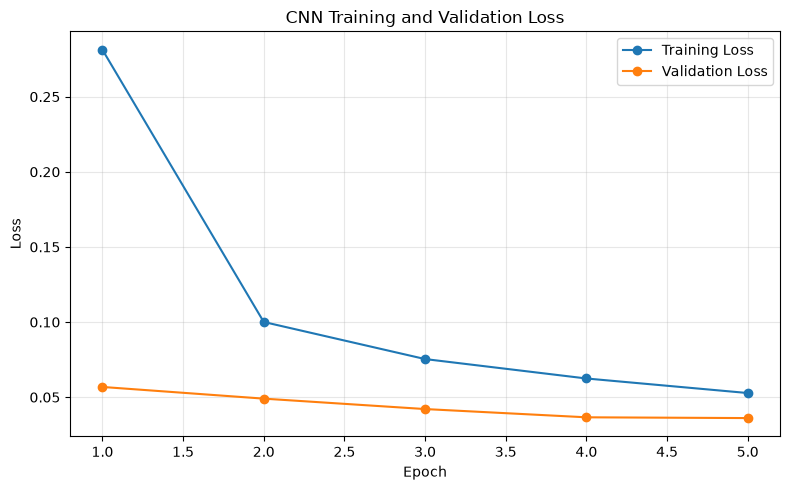

Saved: figures/training_validation_loss.png


In [10]:
plt.figure(figsize=(8, 5))

plt.plot(
    history_df.index,
    history_df["loss"],
    marker="o",
    label="Training Loss"
)

plt.plot(
    history_df.index,
    history_df["val_loss"],
    marker="o",
    label="Validation Loss"
)

plt.title("CNN Training and Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()

save_path = FIGURES_DIR / "training_validation_loss.png"
plt.savefig(save_path, dpi=300, bbox_inches="tight")
plt.show()

print("Saved: figures/training_validation_loss.png")


### Interpretation — Training and validation loss chart

Training loss decreases consistently from **0.2812** in epoch 1 to **0.0528** in epoch 5, showing that the optimizer continues reducing prediction error on the training data. Validation loss also falls in every epoch, from **0.0568** to **0.0361**. Unlike the previous execution, there is **no increase in validation loss at epoch 5**.

The lower validation loss indicates that the model's probability estimates on the validation subset continue improving through the final recorded epoch. Although validation accuracy peaks one epoch earlier, these two observations are compatible because cross-entropy loss considers confidence as well as whether the predicted class is correct.

The five-epoch history does not provide evidence of a sustained rise in validation loss or a widening loss gap associated with pronounced overfitting. Nevertheless, this short run cannot establish that further training would be beneficial. Future experiments could use early stopping and compare checkpoints based on a consistently selected validation metric.

## 9. Evaluate Test Accuracy

In [11]:
test_loss, test_accuracy = model.evaluate(
    X_test_cnn,
    y_test_cat,
    verbose=0
)

print(f"Test Loss: {test_loss:.4f}")
print(f"Test Accuracy: {test_accuracy:.4f}")


Test Loss: 0.0309
Test Accuracy: 0.9900


### Interpretation — Held-out test evaluation

The final CNN achieves **99.00% test accuracy** and **0.0309 test loss** on **10,000 held-out MNIST images**. Accuracy of 0.9900 means approximately **99 of every 100** test images are classified correctly. The confusion matrix confirms the exact count: **9,900 correct predictions** and **100 incorrect predictions**.

The test loss is categorical cross-entropy, which evaluates the probabilities assigned to the correct digit classes rather than only the final class labels. Reporting both accuracy and loss therefore gives a more informative summary than accuracy alone.

These results demonstrate strong performance on the standard MNIST test set. They should not be interpreted as evidence of equivalent performance on real-world photographs, poorly scanned forms, or handwriting collected under different conditions without additional testing.

In [12]:
model_metrics = pd.DataFrame({
    "Metric": [
        "Test Loss",
        "Test Accuracy"
    ],
    "Value": [
        test_loss,
        test_accuracy
    ]
})

model_metrics.to_csv(
    RESULTS_DIR / "model_metrics.csv",
    index=False
)

display(
    model_metrics.style.format({
        "Value": "{:.4f}"
    })
)

print("Saved: results/model_metrics.csv")


,Metric,Value
0,Test Loss,0.0309
1,Test Accuracy,0.9900


Saved: results/model_metrics.csv


### Interpretation — Exported evaluation metrics

The evaluation table records the final **test loss of 0.0309** and **test accuracy of 0.9900**. These figures are consistent with the preceding evaluation output and are exported to `results/model_metrics.csv`.

Saving the metrics in a structured CSV file makes them easier to compare with future model versions and include in portfolio documentation. They represent performance on the **held-out test set**, not the training or validation subsets. In particular, the test accuracy of **99.00%** should not be confused with the **99.00% peak validation accuracy** observed at epoch 4; the percentages happen to match, but they come from different data partitions.

## 10. Generate the Confusion Matrix

In [13]:
y_pred_prob = model.predict(
    X_test_cnn,
    verbose=0
)

y_pred = np.argmax(
    y_pred_prob,
    axis=1
)

cm = confusion_matrix(
    y_test,
    y_pred
)

print("Confusion Matrix:")
print(cm)


Confusion Matrix:
[[ 974    0    1    1    0    0    3    0    1    0]
 [   0 1131    1    1    0    0    2    0    0    0]
 [   1    3 1023    1    0    0    0    4    0    0]
 [   0    0    1 1006    0    2    0    0    1    0]
 [   0    0    1    0  975    0    2    0    0    4]
 [   1    0    0    6    0  882    3    0    0    0]
 [   3    2    0    0    1    3  949    0    0    0]
 [   1    1    6    2    0    0    0 1016    1    1]
 [   5    0    2    1    1    1    2    3  953    6]
 [   3    2    0    1    5    3    0    4    0  991]]


### Interpretation — Numerical confusion matrix

The confusion matrix compares **actual digit labels in rows** with **predicted digit labels in columns**. Correct classifications lie on the main diagonal, which sums to **9,900**. The remaining **100** observations are errors distributed across the off-diagonal cells, consistent with the reported **99.00%** test accuracy.

The most frequent individual misclassifications in this run include **six actual 5s predicted as 3**, **six actual 7s predicted as 2**, and **six actual 8s predicted as 9**. Other notable errors include **five actual 8s predicted as 0** and **five actual 9s predicted as 4**. By comparison, **three actual 6s were predicted as 0**, rather than the eight reported in an earlier run.

These specific error pairs provide a more actionable view than overall accuracy alone: they suggest which digit combinations merit closer examination. However, the matrix does not reveal *why* an individual image was misclassified. Inspecting the original images and predicted probabilities would be needed to investigate handwriting ambiguity, stroke placement, or model confidence.

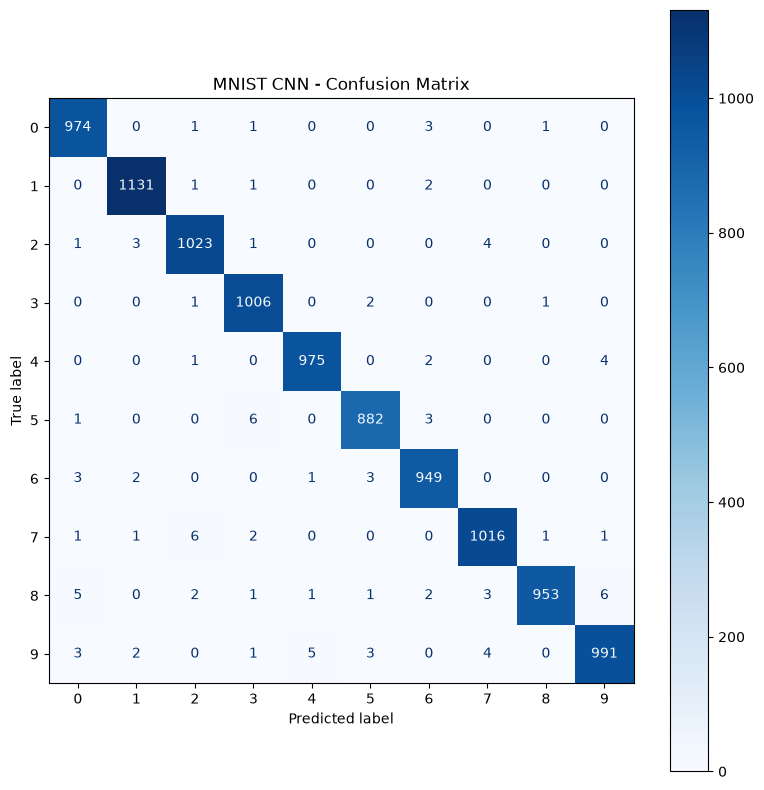

Saved: figures/mnist_confusion_matrix.png


In [14]:
fig, ax = plt.subplots(figsize=(8, 8))

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm
)

disp.plot(
    cmap="Blues",
    values_format="d",
    ax=ax
)

plt.title("MNIST CNN - Confusion Matrix")
plt.tight_layout()

save_path = FIGURES_DIR / "mnist_confusion_matrix.png"
plt.savefig(save_path, dpi=300, bbox_inches="tight")
plt.show()

print("Saved: figures/mnist_confusion_matrix.png")


### Interpretation — Confusion matrix visualization

The heatmap visually confirms that most predictions are correct: the strongest values are concentrated along the main diagonal. Off-diagonal cells are comparatively sparse, consistent with only **100 misclassifications across 10,000 test images**.

The most prominent individual error cells are **5 → 3**, **7 → 2**, and **8 → 9**, each containing **six** observations. These errors are plausible candidates for further inspection because handwritten digits can share curves, loops, or strokes, although the heatmap itself cannot establish the cause.

The heatmap displays **raw counts**, not normalized class-specific error rates. Because the number of test images differs by digit, a class with more errors does not necessarily have the worst error *rate*. A useful next step would calculate precision, recall, and normalized confusion-matrix values for each class, then display examples of misclassified images alongside their predicted probabilities.

## 11. Save the Trained Model

In [15]:
model_path = MODELS_DIR / "mnist_cnn_model.keras"

model.save(model_path)

print("Saved: models/mnist_cnn_model.keras")


Saved: models/mnist_cnn_model.keras


### Interpretation — Saved trained model

The network is saved to `models/mnist_cnn_model.keras`, allowing the learned weights and architecture to be reloaded for inference without repeating the full training process. This is an important deliverable because it turns the notebook from a one-time experiment into a reusable classification artifact. The save confirmation shows that the file was written during this run; it does not independently test loading or predictions after reopening the file.

## 12. Saved Project Outputs

In [16]:
print("Figures:")
for file in sorted(FIGURES_DIR.glob("*.png")):
    print(" -", f"figures/{file.name}")

print("\nResults:")
for file in sorted(RESULTS_DIR.glob("*.csv")):
    print(" -", f"results/{file.name}")

print("\nModels:")
for file in sorted(MODELS_DIR.glob("*")):
    if file.is_file():
        print(" -", f"models/{file.name}")


Figures:
 - figures/mnist_confusion_matrix.png
 - figures/mnist_sample_training_images.png
 - figures/training_validation_accuracy.png
 - figures/training_validation_loss.png

Results:
 - results/model_metrics.csv
 - results/training_history.csv

Models:
 - models/mnist_cnn_model.keras


### Interpretation — Saved project artifacts

The final inventory confirms **four PNG figures**, **two CSV result files**, and **one Keras model file**. The figures document sample images, accuracy, loss, and the confusion matrix; the CSV files preserve the training history and final test metrics; and the model file stores the trained CNN. Keeping these outputs in dedicated directories makes the project easier to audit and present in a GitHub portfolio. The inventory lists files present during this run; it does not establish that the files have been committed to GitHub.

## Conclusion

The CNN achieved **99.00% accuracy on 10,000 held-out MNIST test images**, correctly classifying **9,900** digits and misclassifying **100**, with a final **test loss of 0.0309**. Training accuracy improved from **91.45% to 98.41%** over five epochs. Validation accuracy peaked at **99.00% in epoch 4** and finished at **98.97%**, while validation loss continued decreasing to **0.0361 in epoch 5**. These findings demonstrate strong performance without showing a sustained validation-loss increase during the recorded training period.

The confusion matrix identifies concrete opportunities for targeted error analysis, including **5s predicted as 3s**, **7s predicted as 2s**, and **8s predicted as 9s**. The project also produces reusable artifacts: four figures, two CSV result files, and the trained Keras model. Together, these outputs document a complete image-classification workflow covering preprocessing, CNN design, training, validation, held-out testing, and model export.

## Limitations

The model was evaluated on MNIST rather than real-world scanned forms or photographs, so its performance may differ on noisier or unfamiliar handwriting. The notebook does not report per-class precision and recall, test robustness to image transformations, or compare multiple CNN architectures. Five training epochs also do not establish an optimal stopping point. Future work could inspect misclassified images, evaluate class-specific metrics, and compare training checkpoints or alternative architectures.